# Bonus B1: How to make a LangGraph workflow survive a restart

**Notebook 2 of 2: a refund that waits at the Chinook desk**

## Goal

Run a refund request at the Chinook support desk as a workflow that waits for a reviewer, and let it wait through
a real restart. The request is looked up in the shop's database, a reviewer is told that it is waiting, and
nothing is filed until that person approves. We restart the kernel while it waits and approve it from a new
Python process. Then we read the desk's tables, find that one thing happened twice, and make it safe to repeat.

## What you will learn

- How to read a workflow that is kept in a Python file, and why a job that must survive a restart is kept that
  way.
- How to leave a refund request waiting in a checkpoint file, with the invoice already looked up.
- How to build the workflow again after a kernel restart, read what is waiting, and approve it.
- How to tell from the desk's own tables which node ran twice.
- How to make a write that happens before `interrupt` safe to repeat.

## From the playground to the desk

In notebook 1 a permission slip waited over a weekend. These names carry over:

- The **state** is a dictionary that every step can read. A **node** is a Python function that takes the state
  and returns only what it adds. An **edge** says which node runs next.
- `interrupt(...)` stops a run inside a node. A **checkpointer** keeps the stopped run under a **thread id**,
  and `SqliteSaver` is a checkpointer that keeps it in a SQLite file.
- `Command(resume=...)` continues the run. The waiting node then starts again from its first line.

Now we take it seriously. The lookup reads a shop's database, the workflow writes to tables that other people
act on, and the program stops and starts while a request waits. This notebook restates everything it uses, so
it runs on its own.

⚠️ **This notebook asks you to restart the kernel once, in Part C.** Run the cells one at a time, in order. If you
choose **Run All**, the notebook stops at the restart with a message that says what to do.

## Setup

No model is called in this notebook, so it needs no API key. The setup finds the repository folder, tells Python
where this lab's workflow file is, and names the folder we will write to. `outputs/` is a folder that git
ignores.

In [1]:
from pathlib import Path
import sqlite3
import sys

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# The workflow's code is in a file in this lab's folder: let Python import from there
LAB = ROOT / "bonus" / "B1_LangGraph_Durable_Workflows"
sys.path.insert(0, str(LAB))

OUTPUTS = Path("outputs")
OUTPUTS.mkdir(exist_ok=True)
CHECKPOINT_FILE = OUTPUTS / "checkpoints.db"

print("workflow file:  ", (LAB / "refund_workflow.py").relative_to(ROOT))
print("checkpoint file:", CHECKPOINT_FILE)

workflow file:   bonus/B1_LangGraph_Durable_Workflows/refund_workflow.py
checkpoint file: outputs/checkpoints.db


---

## Part A: Read the refund workflow one node at a time

A rep at the desk takes a call: a customer was charged twice for one invoice. The rep opens a refund request.
Somebody else, a reviewer, has to approve it before it is filed, and the reviewer may not get to it today.

By the time the approval comes, the program may have been stopped and started again. A program that starts
again has only two things: its code, and the files it wrote. So the workflow's code is in a file,
`refund_workflow.py`, in this lab's folder. This notebook imports it now, and will import it again after the
restart. We read it piece by piece before we run it.

A request, as the rep enters it:

In [2]:
request = {"request_id": "R-1001", "invoice_id": 284, "amount": 8.91, "reason": "charged twice"}

print(request)

{'request_id': 'R-1001', 'invoice_id': 284, 'amount': 8.91, 'reason': 'charged twice'}


Four keys: the desk's own number for the request, the invoice, the amount to refund in US dollars, and the
reason. The workflow's state starts with these four and collects more as it goes. `inspect.getsource` prints the
source of something we imported. First the state.

In [3]:
import inspect
import refund_workflow

print(inspect.getsource(refund_workflow.Refund))

class Refund(TypedDict):
    request_id: str         # the desk's number for this request
    invoice_id: int
    amount: float
    reason: str
    customer: str           # added by look_up_invoice
    invoice_total: float    # added by look_up_invoice
    decision: str           # added by review
    status: str             # how the request ended, in words



`Refund` is a `TypedDict`: it names the keys the state may hold. The comments say which node adds each of the
last four.

### The first node looks the invoice up

Nobody should review a refund for an invoice the shop never issued. The first node reads the invoice from
`data/chinook.db`, the shop's database.

In [4]:
print(inspect.getsource(refund_workflow.look_up_invoice))

def look_up_invoice(state):
    """Read the invoice from the shop's database: who it belongs to and its total."""
    print("LOOKED UP invoice", state["invoice_id"])
    with closing(sqlite3.connect(f"file:{CHINOOK}?mode=ro", uri=True)) as shop:
        row = shop.execute(
            "SELECT c.FirstName || ' ' || c.LastName, i.Total FROM invoices i "
            "JOIN customers c ON c.CustomerId = i.CustomerId WHERE i.InvoiceId = ?",
            (state["invoice_id"],)).fetchone()
    if row is None:
        return {"status": f"not filed: no match for invoice {state['invoice_id']}"}
    return {"customer": row[0], "invoice_total": row[1]}



What the node does, step by step:

1. It prints `LOOKED UP`, so that we can see in the output when the node runs.
2. It opens the database **read-only** (`mode=ro`), on a connection of its own, and `closing(...)` closes it when
   the block ends. With one connection per lookup, no connection is shared between requests.
3. One query joins the invoice to its customer and returns the customer's name and the invoice total.
4. If there is no such invoice, the node says so in words, under `status`. If there is, it returns the two facts.

It is a plain function, so we call it by hand: once with our request, and once with an invoice number the shop
does not have.

In [5]:
print(refund_workflow.look_up_invoice(request))
print(refund_workflow.look_up_invoice({"invoice_id": 9999}))

LOOKED UP invoice 284
{'customer': 'Puja Srivastava', 'invoice_total': 8.91}
LOOKED UP invoice 9999
{'status': 'not filed: no match for invoice 9999'}


Invoice 284 belongs to Puja Srivastava and its total is 8.91 US dollars, the amount the rep entered. Invoice
9999 gives *not filed: no match for invoice 9999*. Each call printed its `LOOKED UP` line.

### The second node tells the reviewer, then waits

`review` is the node that stops. Before it stops, it calls `notify_reviewer`. We print both.

In [6]:
print(inspect.getsource(refund_workflow.notify_reviewer))
print(inspect.getsource(refund_workflow.review))

def notify_reviewer(state):
    """Tell the reviewer that a request is waiting: one new row in the notices table."""
    message = (f"Refund request {state['request_id']} is waiting for you: "
               f"invoice {state['invoice_id']}, {state['amount']} US dollars")
    with closing(sqlite3.connect(DESK_DB)) as desk:
        desk.execute("INSERT INTO notices (request_id, message) VALUES (?, ?)", (state["request_id"], message))
        desk.commit()
    print("NOTICE SENT to the reviewer for", state["request_id"])

def review(state):
    """Tell the reviewer, then stop and wait for the decision."""
    notify_reviewer(state)
    decision = interrupt({field: state[field] for field in PACKET_FIELDS})
    if decision == "approve":
        return {"decision": "approve"}
    return {"decision": "reject", "status": f"not filed: the reviewer said: {decision}"}



- `notify_reviewer` adds one row to a table called `notices` and prints `NOTICE SENT`. The row stands for an
  email or a chat message: *a refund request is waiting for you*. The table is in `outputs/desk.db`, a file of
  the desk's own. The shop's database is never written to.
- `review` calls `notify_reviewer` first. Then `interrupt(...)` stops the run and hands the reviewer the facts to
  decide on: the six keys in `PACKET_FIELDS` (`request_id`, `customer`, `invoice_id`, `invoice_total`, `amount`
  and `reason`), with the invoice total next to the amount asked for.
- When the run is resumed, `interrupt(...)` returns the reviewer's decision. The word `approve` approves. Any
  other text is a rejection, and the text is kept as the reason.

We do not call `review` by hand: `interrupt` only works inside a graph that is running.

### The third node files the request, and two routes connect the three nodes

In [7]:
print(inspect.getsource(refund_workflow.file_request))
print(inspect.getsource(refund_workflow.after_lookup))
print(inspect.getsource(refund_workflow.after_review))
print(inspect.getsource(refund_workflow.build_graph))

def file_request(state):
    """Write the refund request: one new row in the refund_requests table."""
    with closing(sqlite3.connect(DESK_DB)) as desk:
        desk.execute("INSERT INTO refund_requests (request_id, invoice_id, amount, reason) VALUES (?, ?, ?, ?)",
                     (state["request_id"], state["invoice_id"], state["amount"], state["reason"]))
        desk.commit()
    print("REFUND REQUEST FILED for", state["request_id"])
    return {"status": "filed"}

def after_lookup(state):
    """A request whose invoice was not found ends here. Every other request goes to review."""
    if state.get("status"):
        return END
    return "review"

def after_review(state):
    """Only an approved request is filed."""
    if state["decision"] == "approve":
        return "file_request"
    return END

def build_graph(checkpointer, review_node=review):
    """Wire the workflow and attach the checkpointer that keeps its runs."""
    builder = StateGraph(Refund)

    builder.add

`file_request` adds one row to `refund_requests`, the table the shop acts on, and prints `REFUND REQUEST FILED`.
This is the write that matters, and it sits in a node of its own, after the review.

`after_lookup` and `after_review` are routes: small functions that read the state and return the name of the
node to run next, or `END`. `after_lookup` returns `END` when the lookup left a `status` (no such invoice) and
`review` otherwise. `after_review` returns `file_request` only for an approval.

`build_graph` wires the nodes:

- `add_edge(START, "look_up_invoice")`: every run begins with the lookup.
- `add_conditional_edges(node, route, [...])`: after the node, call the route and go where it says. The list
  names the places it can point to, so that the drawing can show them.
- `compile(checkpointer=...)` returns the graph we can run, with the checkpointer that will keep its runs.
- `review_node=review` lets us pass another review node later. We use it in Part D.

No model is anywhere in this file. Every route is an `if` that we can read. `draw_mermaid_png()` draws the
graph. The drawing needs the internet: LangGraph sends the node names and the arrows (none of our data) to
[mermaid.ink](https://mermaid.ink). If the cell fails, see Troubleshooting. Every other cell works without it.

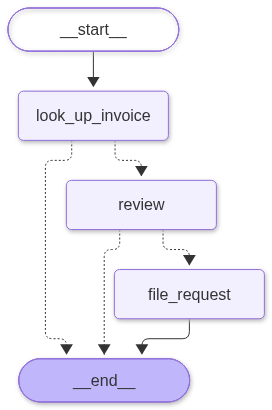

In [8]:
from IPython.display import Image

Image(refund_workflow.build_graph(checkpointer=None).get_graph().draw_mermaid_png())

The dotted arrows are the conditional edges: from `look_up_invoice` to `review` or straight to the end, and from
`review` to `file_request` or to the end.

The next picture shows the same workflow with what each node touches.

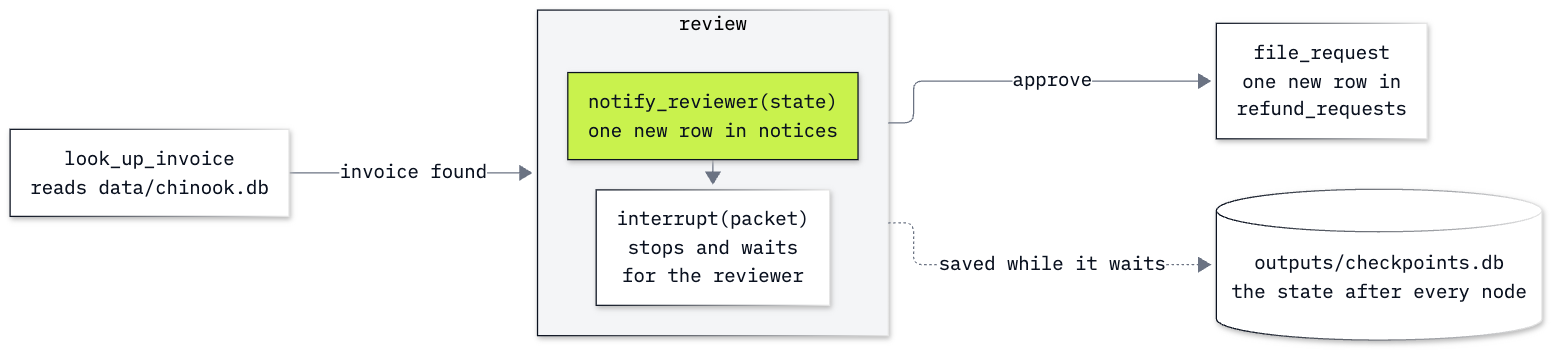

In [9]:
Image(filename="resources/refund_workflow_and_its_files.png", width=760)

The lime box is the notice, a write that happens inside `review` **before** the run stops. The white boxes are
the other steps and the checkpoint file. The picture follows an approved request, so the two routes to the end
are left out.

The dotted arrow, *saved while it waits*, shows the packet from `interrupt(packet)`, the facts handed to the reviewer, going into the checkpoint file. While `review` waits, the file holds the checkpoint saved after `look_up_invoice` and that packet.
`review` has no checkpoint of its own, because it has not finished.

**Checkpoint A.** `look_up_invoice` returns Puja Srivastava and 8.91 for invoice 284, and *not filed: no match
for invoice 9999* for invoice 9999. The drawing has the nodes `look_up_invoice`, `review` and `file_request`,
with dotted arrows from the first two to `__end__`.

---

## Part B: Start a refund and leave it waiting in a file

We build the workflow with a `SqliteSaver`, so that its runs are kept in `outputs/checkpoints.db`.

The cell first deletes the files left by an earlier run of this notebook, so that every run starts fresh. Then
`create_desk_tables` creates the desk's two empty tables in `outputs/desk.db`: `notices` (`request_id`,
`message`) and `refund_requests` (`request_id`, `invoice_id`, `amount`, `reason`). `check_same_thread=False` lets
LangGraph use the connection from the background thread on which it does part of its saving.

`show_desk` prints the `request_id` of every row in `notices`, and the `request_id`, `invoice_id` and `amount` of
every row in `refund_requests`. We call it after every step that could write.

In [10]:
from langgraph.checkpoint.sqlite import SqliteSaver

for old_file in OUTPUTS.glob("*.db*"):
    old_file.unlink()
refund_workflow.create_desk_tables()

saver = SqliteSaver(sqlite3.connect(CHECKPOINT_FILE, check_same_thread=False))
desk = refund_workflow.build_graph(saver)

refund_workflow.show_desk()

notices sent:    none
refund_requests: empty


Both tables are empty. The rep sends the request. Its thread id is the request's own number, `R-1001`, so that
anyone who knows the request can find its run.

The cell prints two things about the run. `invoke` comes back with a key `__interrupt__`: a list with one item,
whose `.value` is what `review` passed to `interrupt(...)`. `get_state(config).next` names the node that runs
when the thread continues.

In [11]:
config = {"configurable": {"thread_id": request["request_id"]}}

paused = desk.invoke(request, config)

print("for the reviewer:", paused["__interrupt__"][0].value)
print("next node:       ", desk.get_state(config).next)
refund_workflow.show_desk()

LOOKED UP invoice 284
NOTICE SENT to the reviewer for R-1001
for the reviewer: {'request_id': 'R-1001', 'customer': 'Puja Srivastava', 'invoice_id': 284, 'invoice_total': 8.91, 'amount': 8.91, 'reason': 'charged twice'}
next node:        ('review',)
notices sent:    ['R-1001']
refund_requests: empty


Read the output from the top:

- `LOOKED UP invoice 284`: the first node ran and finished.
- `NOTICE SENT to the reviewer for R-1001`: `review` started and sent its notice.
- The run stopped there. What the reviewer gets is the request with the two looked-up facts: Puja Srivastava,
  and an invoice total of 8.91 next to the 8.91 asked for.
- `next node` is `review`. The node is waiting; it has not finished.
- The tables: one notice for `R-1001`, and no refund request. Nothing is filed before a person says so.

The waiting run is in the checkpoint file. The file has a table `checkpoints` with one row for every saved
state. Its `metadata` column is LangGraph's short note about the checkpoint, stored as bytes, and
`CAST(... AS TEXT)` shows it as text. We count the checkpoints the way notebook 1 read its file, with plain SQL
on a read-only connection.

In [12]:
file = sqlite3.connect(f"file:{CHECKPOINT_FILE}?mode=ro", uri=True)

for row in file.execute("SELECT thread_id, CAST(metadata AS TEXT) FROM checkpoints"):
    print(row)

file.close()

('R-1001', '{"source": "input", "step": -1, "parents": {}}')
('R-1001', '{"source": "loop", "step": 0, "parents": {}}')
('R-1001', '{"source": "loop", "step": 1, "parents": {}}')


Three checkpoints for the thread `R-1001`. Step -1 is the request arriving and step 0 the request written into
the state. Step 1 was saved after `look_up_invoice` finished. There is none for `review`: LangGraph saves a
checkpoint after a node finishes, and `review` stopped in the middle.

**Checkpoint B.** One `LOOKED UP` line and one `NOTICE SENT` line; the reviewer's facts name Puja Srivastava,
invoice 284, total 8.91 and amount 8.91; `next node: ('review',)`; one notice, no refund request; three
checkpoints, steps -1, 0 and 1.

---

## Part C: Restart the kernel and approve the waiting refund

The reviewer has gone home. Overnight the desk's program is stopped and started again.

### Restart the kernel now

- In VS Code, click **Restart** in the notebook's toolbar.
- In JupyterLab, choose **Kernel → Restart Kernel**.

Then carry on from the next code cell. ⚠️ Do not run the cells above again: Part B's cell deletes the files.

The next cell is the program starting again. It checks first that the restart happened (after one, the name
`desk` is unknown). Then it repeats the setup, imports `refund_workflow` again, and builds the graph with a new
`SqliteSaver` on the same file. Nothing in the cell starts a run.

In [1]:
assert "desk" not in globals(), "Restart the kernel first, then run this cell."

from pathlib import Path
import sqlite3
import sys

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# The workflow's code is in a file in this lab's folder: let Python import from there
LAB = ROOT / "bonus" / "B1_LangGraph_Durable_Workflows"
sys.path.insert(0, str(LAB))

OUTPUTS = Path("outputs")
OUTPUTS.mkdir(exist_ok=True)
CHECKPOINT_FILE = OUTPUTS / "checkpoints.db"

import refund_workflow
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.types import Command

saver = SqliteSaver(sqlite3.connect(CHECKPOINT_FILE, check_same_thread=False))
desk = refund_workflow.build_graph(saver)

print("built again:", list(desk.get_graph().nodes))

built again: ['__start__', 'look_up_invoice', 'review', 'file_request', '__end__']


The same graph, in a new Python process. Request `R-1001` was never run in this process. We ask the checkpointer
what is waiting under that thread id, and read the desk's tables.

In [2]:
config = {"configurable": {"thread_id": "R-1001"}}

saved = desk.get_state(config)

print("next node: ", saved.next)
print("waiting on:", saved.interrupts[0].value)
refund_workflow.show_desk()

next node:  ('review',)
waiting on: {'request_id': 'R-1001', 'customer': 'Puja Srivastava', 'invoice_id': 284, 'invoice_total': 8.91, 'amount': 8.91, 'reason': 'charged twice'}
notices sent:    ['R-1001']
refund_requests: empty


The request survived the restart, with everything the reviewer needs: the customer, the invoice, the total and
the amount. `look_up_invoice` did not run in this process; its two facts came out of the file. The tables are as
we left them: one notice, no refund request.

Reading `.interrupts` first is how we know that a request is waiting on this thread and which one. A resume does not warn you when nothing is waiting on the thread. On a finished thread it runs nothing and returns the final state.
On a thread id that was never used it starts a new run with an empty state, and `look_up_invoice` fails with
`KeyError: 'invoice_id'`.

The reviewer compares 8.91 with 8.91 and approves.

Before you run the cell: the workflow has three print lines, `LOOKED UP`, `NOTICE SENT` and `REFUND REQUEST
FILED`. Which of them will this cell print?

In [3]:
done = desk.invoke(Command(resume="approve"), config)

print("status:", done["status"])
refund_workflow.show_desk()

NOTICE SENT to the reviewer for R-1001
REFUND REQUEST FILED for R-1001
status: filed
notices sent:    ['R-1001', 'R-1001']
refund_requests: [('R-1001', 284, 8.91)]


The request is filed: `refund_requests` holds one row, `R-1001`, invoice 284, 8.91. Now read the two lines above
it, and the notices.

- **No `LOOKED UP` line.** `look_up_invoice` finished before the pause and has a checkpoint. A finished node is
  not run again.
- **`NOTICE SENT` was printed again, and `notices` holds two rows for `R-1001`.** The reviewer was told twice
  about one request.

The checkpoint file keeps the name of the waiting node and not the line where it stopped. On a resume LangGraph
runs `review` again from its first line, and its first line is `notify_reviewer(state)`. Only then does
`interrupt(...)` return the decision.

The graph's own state shows no trace of it: one request, one decision, `status: filed`. We found the second
notice by reading the table the node writes to.

**Key lesson:** on a resume the waiting node is entered a second time, so everything it does before `interrupt`
happens twice. The graph's state does not show the repeat, so count the rows in the tables the workflow writes
to.

**Checkpoint C.** After the restart the thread `R-1001` waits at `review` with Puja's request. The approval
prints `NOTICE SENT` and `REFUND REQUEST FILED` and no `LOOKED UP` line. The tables hold two notices for
`R-1001` and one refund request.

---

## Part D: Make the write before the pause safe to repeat

A second notice is a nuisance. If the line before `interrupt` had filed the refund, the customer would be
refunded twice. Three things keep a write from happening twice:

| Way | In this workflow |
|---|---|
| After the `interrupt` | `file_request` runs only once the decision is there. The workflow already does this for the write that matters |
| A node of its own | the notice in a node that finishes before `review` (the Challenge) |
| Safe to repeat | the notice written so that doing it twice changes nothing |

We take the third. A notice is about one request, and the request has a number. Before sending, we ask the
`notices` table whether that number already has one. `review_once` is `review` with that one change.

In [4]:
from contextlib import closing
from langgraph.types import interrupt


def notify_reviewer_once(state):
    with closing(sqlite3.connect(refund_workflow.DESK_DB)) as desk_db:
        sent = desk_db.execute("SELECT COUNT(*) FROM notices WHERE request_id = ?",
                               (state["request_id"],)).fetchone()[0]
    if sent:
        print("NOTICE ALREADY SENT for", state["request_id"], "(not sent again)")
    else:
        refund_workflow.notify_reviewer(state)


def review_once(state):
    notify_reviewer_once(state)
    decision = interrupt({field: state[field] for field in refund_workflow.PACKET_FIELDS})
    if decision == "approve":
        return {"decision": "approve"}
    return {"decision": "reject", "status": f"not filed: the reviewer said: {decision}"}


desk_v2 = refund_workflow.build_graph(saver, review_node=review_once)

`desk_v2` is the same workflow on the same checkpoint file, with `review_once` in the place of `review`.

A second request: Helena Holý was charged twice for invoice 393, 1.98 US dollars. It gets the number `R-1002`.

In [5]:
request = {"request_id": "R-1002", "invoice_id": 393, "amount": 1.98, "reason": "charged twice"}
config = {"configurable": {"thread_id": request["request_id"]}}

paused = desk_v2.invoke(request, config)

print("for the reviewer:", paused["__interrupt__"][0].value)

LOOKED UP invoice 393
NOTICE SENT to the reviewer for R-1002
for the reviewer: {'request_id': 'R-1002', 'customer': 'Helena Holý', 'invoice_id': 393, 'invoice_total': 1.98, 'amount': 1.98, 'reason': 'charged twice'}


The lookup ran, the notice went out, and the run waits with Helena's facts: invoice 393, total 1.98, amount
1.98.

The reviewer approves. We do not restart this time: a resume starts the waiting node again from its first line
with or without a restart.

In [6]:
done = desk_v2.invoke(Command(resume="approve"), config)

print("status:", done["status"])
refund_workflow.show_desk()

NOTICE ALREADY SENT for R-1002 (not sent again)
REFUND REQUEST FILED for R-1002
status: filed
notices sent:    ['R-1001', 'R-1001', 'R-1002']
refund_requests: [('R-1001', 284, 8.91), ('R-1002', 393, 1.98)]


`NOTICE ALREADY SENT for R-1002 (not sent again)`: `review_once` did start again from its first line, found the
notice in the table, and sent nothing. Then the request was filed.

The tables tell the two versions apart. `R-1001`, on the first workflow, has two notices. `R-1002` has one.
Each has one refund request.

The fix did not stop the node from running twice: a waiting node starts again from its first line on every
resume. It made the second run harmless, by reading the `notices` table before writing to it.

**Checkpoint D.** Helena's request prints `LOOKED UP invoice 393` and `NOTICE SENT` and waits. The approval
prints `NOTICE ALREADY SENT for R-1002 (not sent again)` and `REFUND REQUEST FILED`. `notices` holds `R-1001`
twice and `R-1002` once; `refund_requests` holds two rows.

---

## In production

- **Put a unique key on the table.** Our check reads the table and then writes, and two programs doing that
  at the same moment could both write. With a unique key on `request_id`, the database rejects the second row.
  Payment services offer the same thing as an *idempotency key*: send the same key twice and the second call
  does nothing.
- **A node that fails halfway is run again too.** `file_request` sits after the approval, and it still should be
  safe to repeat, for the day the program stops between its write and its checkpoint.
- **Checkpoints in a database server.** `SqliteSaver` suits one machine. For a program on several servers
  LangGraph has `PostgresSaver`, in the package `langgraph-checkpoint-postgres`.
- **The checkpoint file holds customer data.** The state is saved as it is: names, invoices, amounts. Protect the
  file like the database it was read from.
- **Anyone who knows a thread id can resume its run.** Whoever can send `R-1001` can approve it. Check that the
  person who resumes may decide on that request.

## What you can do now

- Read a workflow kept in a file, node by node, and say why it is kept there (Part A).
- Start a request, leave it waiting in a checkpoint file, and say which nodes have a checkpoint (Part B).
- Build the workflow again after a restart, read what is waiting, and approve it (Part C).
- Find from the tables a workflow writes to that its waiting node ran twice (Part C).
- Make a write before `interrupt` safe to repeat (Part D).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ValueError: Failed to reach https://mermaid.ink API while trying to render your graph` | the drawing cell sends the graph's description to mermaid.ink, and the service could not be reached | check the internet connection and run the cell again; or run `print(refund_workflow.build_graph(None).get_graph().draw_mermaid())`, which prints the same nodes and arrows as text. Every other cell works without the drawing |
| `AssertionError: Restart the kernel first, then run this cell.` | the cell after the restart ran in the old kernel, for example with Run All | restart the kernel, then run from that cell downwards |
| `IndexError: tuple index out of range` at `saved.interrupts[0]` | nothing is waiting on the thread `R-1001`: the request was already approved, or Part B's cell ran again after the restart and emptied the files | start again from the first cell |
| `ModuleNotFoundError: No module named 'refund_workflow'` | the setup cell did not run, so Python does not look in this lab's folder | run the setup cell (after the restart, the cell under *Restart the kernel now*) |
| `ProgrammingError: SQLite objects created in a thread can only be used in that same thread.` | the connection given to `SqliteSaver` was opened without `check_same_thread=False` | open it with `sqlite3.connect(CHECKPOINT_FILE, check_same_thread=False)` |

## Challenge

Both tasks run in the kernel you have now. No restart is needed.

1. **Give the notice a node of its own.** Build a graph in the notebook from the file's pieces:
   `refund_workflow.look_up_invoice`, a new node `notify` that calls `refund_workflow.notify_reviewer(state)`
   and returns `{}`, a new node `review` that holds only the `interrupt` and the decision, and
   `refund_workflow.file_request`. Write a route of your own that sends a found invoice to `notify`; the file's
   `after_review` works as it is. Import `StateGraph`, `START` and `END` from `langgraph.graph`, start from
   `StateGraph(refund_workflow.Refund)`, and compile with `checkpointer=saver`. Send request `R-1003`: Puja
   Srivastava was charged twice for invoice 229, 13.86 US dollars. Approve it.

   Expected: `NOTICE SENT` is printed once, by the first cell; the approval prints only `REFUND REQUEST FILED`;
   `notices` holds one row for `R-1003`.

2. **Reject a request.** On `desk_v2`, send request `R-1004`: Helena Holý, invoice 175, 1.98 US dollars, charged
   twice. Resume with a reason in place of `approve`, for example *billing shows one charge for invoice 175*.

   Expected: no `REFUND REQUEST FILED` line; the status reads *not filed: the reviewer said:* followed by your
   reason; `refund_requests` has no row for `R-1004`, and `notices` has one.

The worked solution, run with its outputs, is in `solved/b1b_durable_workflows_at_the_desk_solution.ipynb`.

## Going further

- **Go back in a thread.** `get_state_history(config)` returns every checkpoint of a thread, and `update_state`
  starts a new branch from an earlier one, for example to correct an amount and run the review again.
- **How soon a checkpoint is written.** `invoke(..., durability="sync")` writes every checkpoint before the next
  step starts. The default, `"async"`, writes while the next step runs.
- **An encrypted checkpoint file.** `SqliteSaver(connection, serde=EncryptedSerializer.from_pycryptodome_aes())`
  encrypts the saved state. It needs the `pycryptodome` package and a key in the environment variable
  `LANGGRAPH_AES_KEY`.

## Resources

- [Interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts): `interrupt`, `Command(resume=...)`,
  and the rule that work before an interrupt must be safe to repeat
- [Checkpointers](https://docs.langchain.com/oss/python/langgraph/checkpointers): `SqliteSaver`, `PostgresSaver`,
  threads, `get_state`, durability modes and encryption
- [Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api): state, nodes, edges and conditional
  edges
- [Time travel](https://docs.langchain.com/oss/python/langgraph/use-time-travel): going back to an earlier
  checkpoint and branching from it
- [Python `sqlite3`](https://docs.python.org/3/library/sqlite3.html): connections, `mode=ro` and
  `check_same_thread`

Back to [this lab's README](README.md).